# 01 · Exploratory Data Analysis

**CRISP-DM phase: Data understanding.**

Goal: understand who buys, how buyers behave differently, and turn each finding into a modelling decision. Data is loaded through `src.data.loader.load_data()`, the same function the training code and API use.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use the code in src/
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import seaborn as sns

from src.config.settings import get_settings
from src.data.loader import load_data

settings = get_settings()
TARGET = settings.target

# Two fixed colours used everywhere: non-buyers blue, buyers orange.
NON_BUYER, BUYER = "#2a78d6", "#eb6834"
CLASS_COLORS = {0: NON_BUYER, 1: BUYER}
MONTH_ORDER = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

df = load_data()
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Converted
0,1,14.6517,0,0.0000,19,283.8812,0.008014,0.042106,68.579222,0.0,June,1,2,1,1,Returning_Visitor,False,1
1,1,18.9189,2,54.9802,15,1241.7638,0.032395,0.058101,0.000000,0.0,May,2,1,8,12,Returning_Visitor,False,0
2,1,30.0198,0,0.0000,23,365.3384,0.006802,0.029451,0.000000,0.0,Mar,1,2,1,3,New_Visitor,True,0
3,1,6.5566,0,0.0000,6,687.4788,0.039577,0.104395,0.000000,0.6,Dec,1,1,1,2,Returning_Visitor,True,0
4,1,112.5842,1,36.3523,19,656.4535,0.004594,0.038321,0.000000,0.0,Mar,2,1,2,5,Returning_Visitor,False,0


## 1. Data quality

In [2]:
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.describe().T.round(2)

Shape: (12000, 18)
Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Administrative,12000.0,1.89,1.47,0.0,1.00,2.00,3.00,11.00
Administrative_Duration,12000.0,42.31,49.03,0.0,11.77,28.51,56.38,659.47
Informational,12000.0,0.55,0.75,0.0,0.00,0.00,1.00,6.00
Informational_Duration,12000.0,13.55,25.07,0.0,0.00,0.00,19.93,397.17
ProductRelated,12000.0,19.83,13.17,0.0,11.00,17.00,25.00,156.00
ProductRelated_Duration,12000.0,723.10,763.56,0.0,268.16,499.43,902.04,10154.16
BounceRates,12000.0,0.02,0.02,0.0,0.01,0.02,0.03,0.09
ExitRates,12000.0,0.05,0.03,0.0,0.04,0.05,0.07,0.16
PageValues,12000.0,12.23,25.86,0.0,0.00,0.00,12.91,418.11
SpecialDay,12000.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


**Takeaway:** 12,000 sessions, no missing values, no duplicates. Note that `Month` has no Jan or Apr, so the encoder must handle unseen months safely (`handle_unknown="ignore"`).

## 2. Conversion rate (the imbalance)

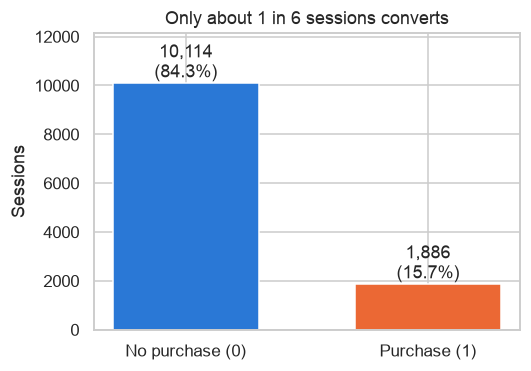

Conversion rate: 15.7%
Accuracy of always predicting 'no purchase': 84.3%


In [3]:
rate = df[TARGET].mean()
counts = df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["No purchase (0)", "Purchase (1)"], counts.values, color=[NON_BUYER, BUYER], width=0.6)
for i, value in enumerate(counts.values):
    ax.text(i, value, f"{value:,}\n({value / len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("Sessions")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Only about 1 in 6 sessions converts")
plt.show()

print(f"Conversion rate: {rate:.1%}")
print(f"Accuracy of always predicting 'no purchase': {1 - rate:.1%}")

**Takeaway:** 15.7% of sessions convert. Always predicting "no purchase" already scores 84.3% accuracy, so accuracy is useless here. **Decision:** lead with PR-AUC and recall, use stratified splits, and handle the imbalance (class weights / SMOTE / threshold).

## 3. How buyers differ from non-buyers

In [4]:
key_features = ["PageValues", "ProductRelated", "ProductRelated_Duration", "ExitRates", "BounceRates"]
df.groupby(TARGET)[key_features].median().T.rename(columns={0: "non-buyer median", 1: "buyer median"}).round(3)

Converted,non-buyer median,buyer median
PageValues,0.000,39.488
ProductRelated,15.000,32.000
ProductRelated_Duration,447.737,933.782
ExitRates,0.058,0.030
BounceRates,0.022,0.007


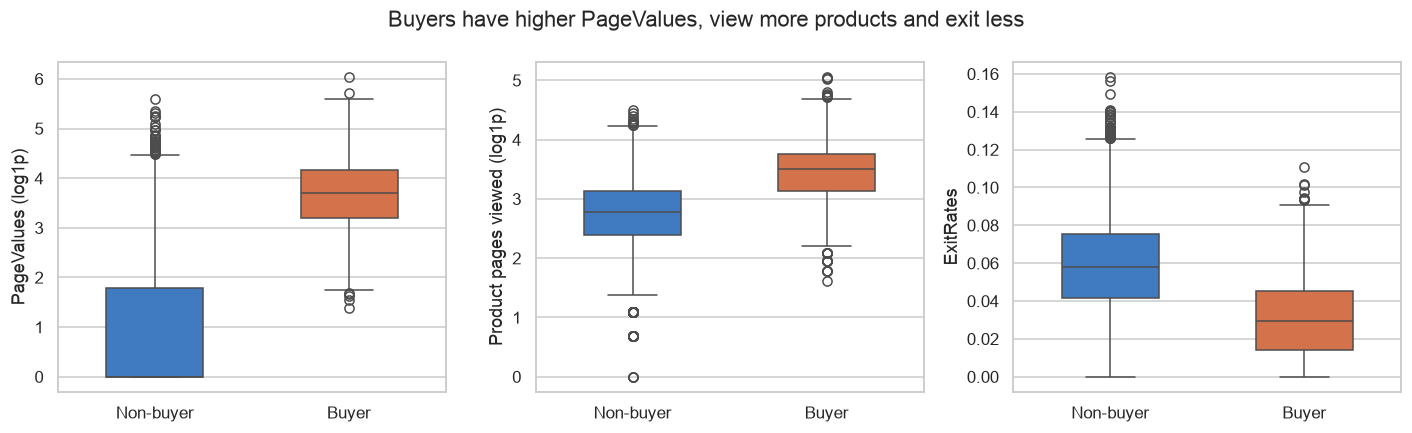

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plots = [
    ("PageValues", True, "PageValues (log1p)"),
    ("ProductRelated", True, "Product pages viewed (log1p)"),
    ("ExitRates", False, "ExitRates"),
]
for ax, (col, use_log, label) in zip(axes, plots):
    values = np.log1p(df[col]) if use_log else df[col]
    sns.boxplot(x=df[TARGET], y=values, hue=df[TARGET], palette=CLASS_COLORS,
                legend=False, width=0.5, ax=ax)
    ax.set_xticks([0, 1], ["Non-buyer", "Buyer"])
    ax.set_xlabel("")
    ax.set_ylabel(label)
fig.suptitle("Buyers have higher PageValues, view more products and exit less")
plt.tight_layout()
plt.show()

**Takeaway:** buyers view about twice as many product pages (median 32 vs 15), spend about twice as long on them, and have about half the exit rate. PageValues separates the classes most strongly. **Decision:** engagement features carry real signal; engineered ratios such as time-per-product-page are worth trying in Week 2.

### Leakage check: PageValues

**Data leakage** means the model learns from information it would not have at the moment it makes a prediction. Scores look great in testing and then fall apart in production.

We want to score sessions **mid-visit**, while there is still time to nudge the visitor. So for each feature we ask: is this value known at that point?

In [6]:
zero_pv = df["PageValues"] == 0
print(f"Share of buyers with PageValues = 0:     {zero_pv[df[TARGET] == 1].mean():.1%}")
print(f"Share of non-buyers with PageValues = 0: {zero_pv[df[TARGET] == 0].mean():.1%}")
print(f"Conversion rate when PageValues = 0: {df.loc[zero_pv, TARGET].mean():.1%}")
print(f"Conversion rate when PageValues > 0: {df.loc[~zero_pv, TARGET].mean():.1%}")

Share of buyers with PageValues = 0:     0.0%
Share of non-buyers with PageValues = 0: 65.4%
Conversion rate when PageValues = 0: 0.0%
Conversion rate when PageValues > 0: 35.0%


**Takeaway:** *no* buyer has PageValues = 0, while 65% of non-buyers do, and a session with PageValues = 0 never converts. PageValues is the average value of the pages a visitor saw on the way to a transaction, so it mostly fills in as the visitor heads to checkout. In a sense it records the purchase rather than predicting it.

**Decision: PageValues is left out of the model to prevent data leakage.** Mid-session, it is either not known yet or is already a sign that the purchase is happening. It is listed under `features.leakage_excluded` in `config.yaml`.

Leaving it out costs a lot on paper. In cross-validation, PR-AUC drops from about 0.85 to about 0.53 (see `reports/model_comparison.csv`). The higher number is not reachable when scoring mid-session, so the lower one is the honest estimate. The dashboard will show the two side by side.

## 4. Seasonality: Month and SpecialDay

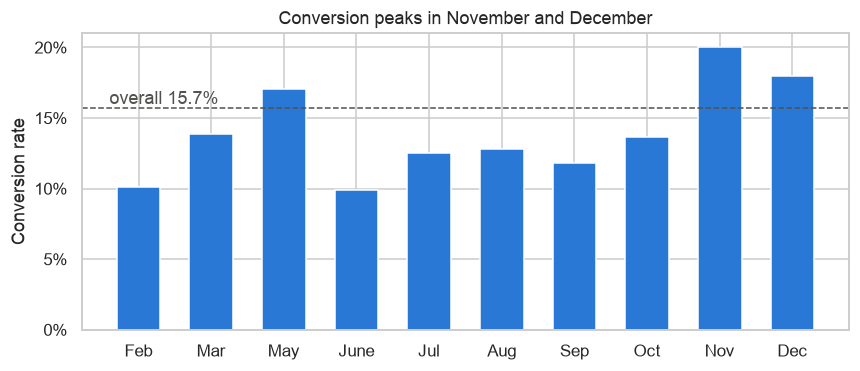

,conversion_rate,sessions
Month,,
Feb,0.101,377
Mar,0.139,2112
May,0.171,3554
June,0.099,598
Jul,0.125,440
Aug,0.128,530
Sep,0.118,600
Oct,0.136,718
Nov,0.200,2235


In [7]:
by_month = df.groupby("Month")[TARGET].agg(conversion_rate="mean", sessions="size")
by_month = by_month.reindex(MONTH_ORDER)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_month.index, by_month["conversion_rate"], color=NON_BUYER, width=0.6)
ax.axhline(rate, color="#52514e", linestyle="--", linewidth=1)
ax.text(-0.4, rate, f"overall {rate:.1%}", va="bottom", ha="left", color="#52514e")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Conversion rate")
ax.set_title("Conversion peaks in November and December")
plt.show()

by_month.round(3)

**Takeaway:** November (20.0%) and December (17.9%) convert best; June and February are lowest (~10%). May and November together hold almost half of all sessions. **Decision:** Month is useful, so one-hot encode it.

In [8]:
df.groupby("SpecialDay")[TARGET].agg(conversion_rate="mean", sessions="size").round(3)

,conversion_rate,sessions
SpecialDay,,
0.0,0.156,10799
0.2,0.160,243
0.4,0.164,219
0.6,0.173,231
0.8,0.178,247
1.0,0.142,261


**Takeaway:** 90% of sessions have SpecialDay = 0, and the conversion rate barely moves across its values (14–18%). **Decision:** probably a weak feature; let feature importance decide in Week 2.

## 5. Visitor type and weekend

In [9]:
for col in ["VisitorType", "Weekend"]:
    display(df.groupby(col)[TARGET].agg(conversion_rate="mean", sessions="size").round(3))

,conversion_rate,sessions
VisitorType,,
New_Visitor,0.102,1564
Other,0.150,133
Returning_Visitor,0.166,10303


,conversion_rate,sessions
Weekend,,
False,0.158,9206
True,0.156,2794


**Takeaway:** returning visitors convert more (16.6%) than new visitors (10.2%), and 86% of sessions are returning visitors. Weekend makes no difference (15.8% vs 15.6%). **Decision:** keep VisitorType; Weekend is likely noise.

## 6. The int-coded ID columns are categories

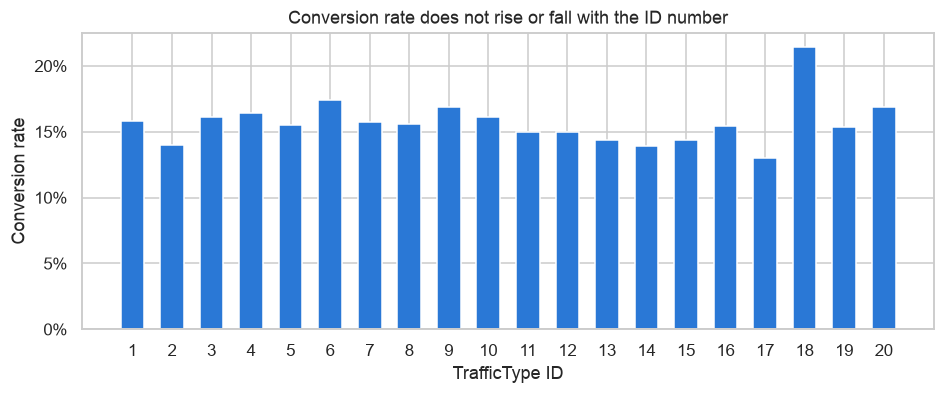

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
by_traffic = df.groupby("TrafficType")[TARGET].mean()
ax.bar(by_traffic.index.astype(str), by_traffic.values, color=NON_BUYER, width=0.6)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("TrafficType ID")
ax.set_ylabel("Conversion rate")
ax.set_title("Conversion rate does not rise or fall with the ID number")
plt.show()

**Takeaway:** the conversion rate jumps up and down between IDs with no order, so TrafficType 20 is not "more" than TrafficType 1. **Decision:** one-hot encode OperatingSystems, Browser, Region and TrafficType; never scale them as numbers.

## 7. Skewed numeric columns

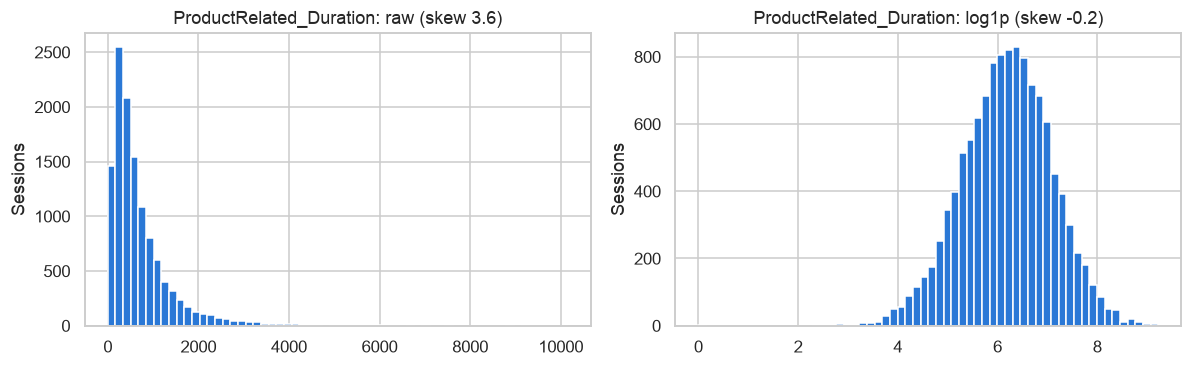

,skew,share_of_zeros
Administrative,0.91,0.17
Administrative_Duration,2.89,0.17
Informational,1.47,0.58
Informational_Duration,3.84,0.58
ProductRelated,2.05,0.00
ProductRelated_Duration,3.64,0.00
PageValues,3.99,0.55
BounceRates,0.48,0.12
ExitRates,0.14,0.01
SpecialDay,3.49,0.90


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
col = "ProductRelated_Duration"
axes[0].hist(df[col], bins=60, color=NON_BUYER)
axes[0].set_title(f"{col}: raw (skew {df[col].skew():.1f})")
axes[1].hist(np.log1p(df[col]), bins=60, color=NON_BUYER)
axes[1].set_title(f"{col}: log1p (skew {np.log1p(df[col]).skew():.1f})")
for ax in axes:
    ax.set_ylabel("Sessions")
plt.tight_layout()
plt.show()

numeric = settings.numeric_features
summary = df[numeric].agg(["skew"]).T
summary["share_of_zeros"] = (df[numeric] == 0).mean()
summary.round(2)

**Takeaway:** durations and PageValues have a long right tail (skew 3–4) and many zeros (58% of sessions never visit an informational page). log1p pulls the tail in and keeps zeros at zero. **Decision:** log1p + StandardScaler for counts, durations and PageValues; plain StandardScaler for the bounded rates.

## 8. Correlations

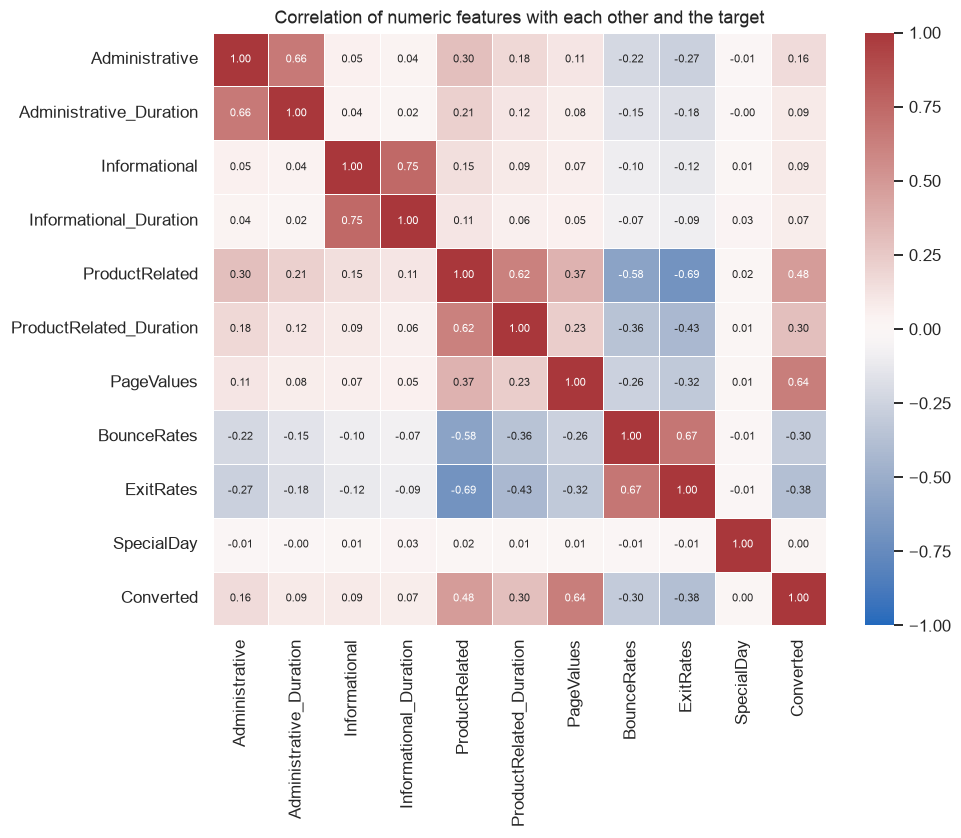

ExitRates                 -0.381
BounceRates               -0.301
SpecialDay                 0.004
Informational_Duration     0.071
Informational              0.086
Administrative_Duration    0.090
Administrative             0.161
ProductRelated_Duration    0.298
ProductRelated             0.478
PageValues                 0.640
Name: Converted, dtype: float64

In [12]:
corr = df[settings.numeric_features + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, ax=ax)
ax.set_title("Correlation of numeric features with each other and the target")
plt.show()

corr[TARGET].drop(TARGET).sort_values().round(3)

**Takeaway:** PageValues (+0.64) and ProductRelated (+0.48) are most positively related to buying; ExitRates (−0.38) and BounceRates (−0.30) most negatively. BounceRates and ExitRates correlate with each other (0.67), as do each page count and its duration (0.62–0.75), and more product pages go with lower exit rates (−0.69). **Decision:** watch for redundancy in Logistic Regression; tree models cope fine.

## 9. Interactive view (Plotly)

In [13]:
month_visitor = (
    df.groupby(["Month", "VisitorType"])[TARGET]
    .agg(conversion_rate="mean", sessions="size")
    .reset_index()
)

fig = px.bar(
    month_visitor,
    x="Month",
    y="conversion_rate",
    color="VisitorType",
    barmode="group",
    hover_data={"sessions": True, "conversion_rate": ":.1%"},
    category_orders={"Month": MONTH_ORDER},
    color_discrete_sequence=["#2a78d6", "#eb6834", "#1baf7a"],
    title="Conversion rate by month and visitor type (hover for session counts)",
)
fig.update_layout(yaxis_tickformat=".0%", template="plotly_white")
fig.show()

**Takeaway:** returning visitors out-convert new visitors in most months. The "Other" group has only 133 sessions, so its bars are noisy (hover to see the counts).

## Summary: what EDA decided

| Finding | Modelling decision |
|---|---|
| 15.7% conversion, accuracy is misleading | PR-AUC + recall first; stratified split; imbalance strategy |
| No buyer has PageValues = 0 (65% of non-buyers do) | **Excluded from the model to prevent leakage** (we score mid-session); with/without comparison shown in the dashboard |
| Buyers view more product pages and exit less | Engagement features matter; engineer ratios in Week 2 |
| Conversion peaks in Nov/Dec | One-hot encode Month; unseen months ignored |
| ID columns show no order | One-hot encode OS, Browser, Region, TrafficType |
| Durations heavily skewed with many zeros | log1p + StandardScaler |
| Weekend and SpecialDay look weak | Let feature importance decide in Week 2 |